In [1]:
import os
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    silhouette_score,
)
from sklearn.cluster import KMeans

DATA_PATH = "../data/dataset.csv"
OUTPUT_DIR = "../output"
os.makedirs(f"{OUTPUT_DIR}/figures", exist_ok=True)
RANDOM_STATE = 42

TEXT_COL = "review"
STOP = set(stopwords.words("english"))
TOKEN_PATTERN = r"[a-z][a-z']+"

# Data Analysis and Preprocessing


In [2]:
df = pd.read_csv(DATA_PATH)
display(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


Shape: (50000, 2)
Columns: ['review', 'sentiment']


In [3]:
print(df.dtypes)
df.info()
display(df.describe(include="all"))
print(df["sentiment"].value_counts())

review       str
sentiment    str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 63.6 MB


,review,sentiment
count,50000,50000
unique,49582,2
top,Loved today's show!!! It was a variety and not...,positive
freq,5,25000


sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [4]:
print("Missing values per column:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

shape_before = df.shape
df = df.drop_duplicates().reset_index(drop=True)
print("Shape before:", shape_before)
print("Shape after: ", df.shape)
print(df["sentiment"].value_counts())


Missing values per column:
 review       0
sentiment    0
dtype: int64
Duplicate rows: 418
Shape before: (50000, 2)
Shape after:  (49582, 2)
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


In [5]:
long_positive = df.loc[(df["sentiment"] == "positive") & (df["review"].str.len() > 2000)]
print(len(long_positive), "long positive reviews")
long_positive.head()

4368 long positive reviews


,review,sentiment
26,"""The Cell"" is an exotic masterpiece, a dizzyin...",positive
29,'War movie' is a Hollywood genre that has been...,positive
30,"Taut and organically gripping, Edward Dmytryk'...",positive
31,"""Ardh Satya"" is one of the finest film ever ma...",positive
33,One of the most significant quotes from the en...,positive


In [6]:
df.iloc[0:7]

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
5,"Probably my all-time favorite movie, a story o...",positive
6,I sure would like to see a resurrection of a u...,positive


In [7]:
df.iloc[np.r_[0:3, 100:103]]

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
100,This short film that inspired the soon-to-be f...,positive
101,"Okay, last night, August 18th, 2004, I had the...",negative
102,I bought this game on an impulse buy from walm...,positive


In [8]:
df["label"] = df["sentiment"].replace({"negative": 0, "positive": 1})
df["sentiment"] = df["sentiment"].astype("category")
df["label"] = df["label"].astype(int)

df["char_count"] = df["review"].str.len()
df["word_count"] = df["review"].str.split().str.len()
df

,review,sentiment,label,char_count,word_count
0,One of the other reviewers has mentioned that ...,positive,1,1761,307
1,A wonderful little production. <br /><br />The...,positive,1,998,162
2,I thought this was a wonderful way to spend ti...,positive,1,926,166
3,Basically there's a family where a little boy ...,negative,0,748,138
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1,1317,230
...,...,...,...,...,...
49577,I thought this movie did a down right good job...,positive,1,1008,194
49578,"Bad plot, bad dialogue, bad acting, idiotic di...",negative,0,642,112
49579,I am a Catholic taught in parochial elementary...,negative,0,1280,230
49580,I'm going to have to disagree with the previou...,negative,0,1234,212


In [9]:
N = 5000
simple = df.sample(n=N, random_state=RANDOM_STATE)
print(len(simple))

5000


In [10]:
stratified = (
    df.groupby("sentiment")
      .sample(frac=N / len(df), random_state=RANDOM_STATE)
)

print(len(stratified))

5000


In [11]:
df["cluster_id"] = np.arange(len(df)) // (len(df) // 100)
rng = np.random.default_rng(RANDOM_STATE)
chosen = rng.choice(df["cluster_id"].unique(), size=10, replace=False)
cluster = df[df["cluster_id"].isin(chosen)]
print("clusters chosen:", sorted(chosen), "| rows:", len(cluster))

clusters chosen: [np.int64(8), np.int64(9), np.int64(20), np.int64(41), np.int64(61), np.int64(69), np.int64(71), np.int64(83), np.int64(95), np.int64(97)] | rows: 4950


In [12]:
comparison = pd.DataFrame({
    "original": df["sentiment"].value_counts(normalize=True),
    "simple": simple["sentiment"].value_counts(normalize=True),
    "stratified": stratified["sentiment"].value_counts(normalize=True),
    "cluster": cluster["sentiment"].value_counts(normalize=True),
}).round(4)
display(comparison)
print({"simple": len(simple), "stratified": len(stratified), "cluster": len(cluster)})

,original,simple,stratified,cluster
sentiment,,,,
negative,0.4981,0.502,0.4982,0.499
positive,0.5019,0.498,0.5018,0.501


{'simple': 5000, 'stratified': 5000, 'cluster': 4950}


In [13]:
df["unique_word_count"] = df["review"].str.lower().str.split().apply(lambda w: len(set(w)))
df["avg_word_length"] = df["char_count"] / df["word_count"]

features = ["char_count", "word_count", "unique_word_count", "avg_word_length"]
df[features].describe().head()

,char_count,word_count,unique_word_count,avg_word_length
count,49582.000000,49582.000000,49582.000000,49582.000000
mean,1310.568230,231.350167,148.145658,5.634475
std,990.762238,171.542020,88.897414,0.340699
min,32.000000,4.000000,4.000000,2.236486
25%,699.000000,126.000000,91.000000,5.411765


,char_count,word_count,unique_word_count,avg_word_length,label
char_count,1.000,0.997,0.990,0.182,0.016
word_count,0.997,1.000,0.987,0.120,0.010
unique_word_count,0.990,0.987,1.000,0.179,0.000
avg_word_length,0.182,0.120,0.179,1.000,0.051
label,0.016,0.010,0.000,0.051,1.000


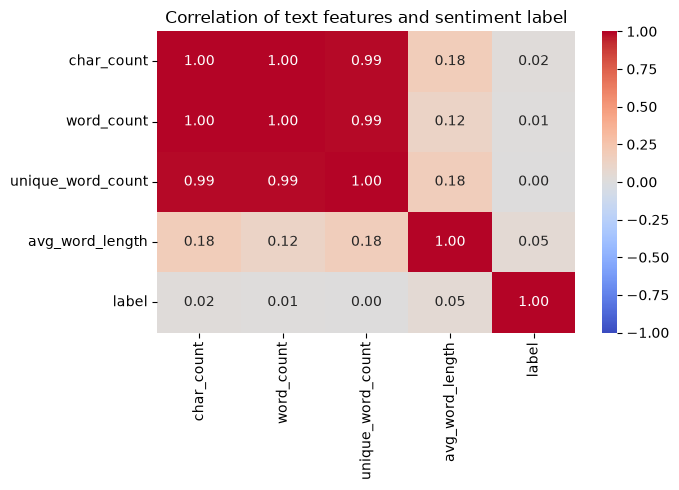

In [14]:
num_cols = features + ["label"]
corr = df[num_cols].corr()
display(corr.round(3))

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation of text features and sentiment label")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/correlation_heatmap.png", dpi=150)
plt.show()


# Text Analysis

In [15]:
HTML_RE = re.compile(r'<[^>]+>')
URL_RE = re.compile(r'https?://\S+|www\.\S+')
NUM_RE  = re.compile(r'\d+')
PUNCT_RE = re.compile(r"[^a-z\s']") 

def clean_text(t):
    if pd.isna(t):
        return ''
    t = str(t).lower()
    t = HTML_RE.sub(' ', t)
    t = URL_RE.sub(' ', t)
    t = NUM_RE.sub(' ', t)
    t = PUNCT_RE.sub(' ', t)
    return re.sub(r'\s+', ' ', t).strip()

df['cleaned_text'] = df[TEXT_COL].apply(clean_text)
print(df[TEXT_COL].iloc[0], '\n')
print(df['cleaned_text'].iloc[0])
print('\nMissing text:', df[TEXT_COL].isna().sum(),
      '| Empty after cleaning:', (df['cleaned_text'] == '').sum())

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due to the fac

In [16]:
def tokenize(s):
    return [w.strip("'") for w in s.split() if w.strip("'")]

df["tokens"] = df["cleaned_text"].apply(tokenize)
df["clean_word_count"] = df["tokens"].apply(len)
df["clean_char_len"] = df["cleaned_text"].str.len()

display(df[["cleaned_text", "word_count", "clean_word_count", "char_count", "clean_char_len"]].head(5))

all_tokens = [w for toks in df["tokens"] for w in toks]

stats = pd.DataFrame({
    "Metric": ["Total tokens", "Unique words", "Average words per record"],
    "Value": [len(all_tokens), len(set(all_tokens)), round(df["clean_word_count"].mean(), 2)],
})
display(stats)

,cleaned_text,word_count,clean_word_count,char_count,clean_char_len
0,one of the other reviewers has mentioned that ...,307,307,1761,1676
1,a wonderful little production the filming tech...,162,158,998,943
2,i thought this was a wonderful way to spend ti...,166,164,926,878
3,basically there's a family where a little boy ...,138,130,748,686
4,petter mattei's love in the time of money is a...,230,225,1317,1243


,Metric,Value
0,Total tokens,11397912.00
1,Unique words,109472.00
2,Average words per record,229.88


,word,count
0,the,662914
1,and,322088
2,a,320776
3,of,287338
4,to,266103
5,is,209633
6,in,185410
7,it,155832
8,i,153792
9,this,149799


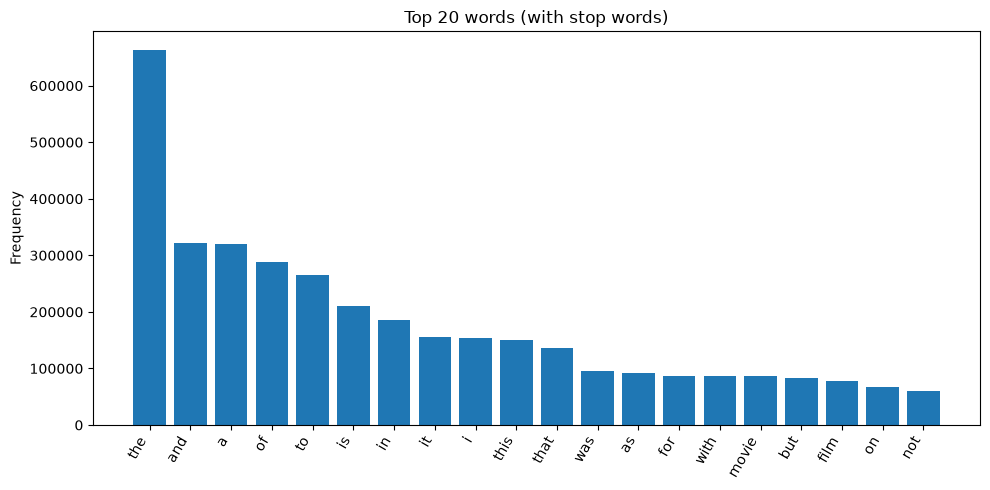

,word,count
0,movie,86470
1,film,77205
2,one,52692
3,like,39842
4,good,29539
5,time,24888
6,even,24669
7,would,24036
8,really,22923
9,story,22867


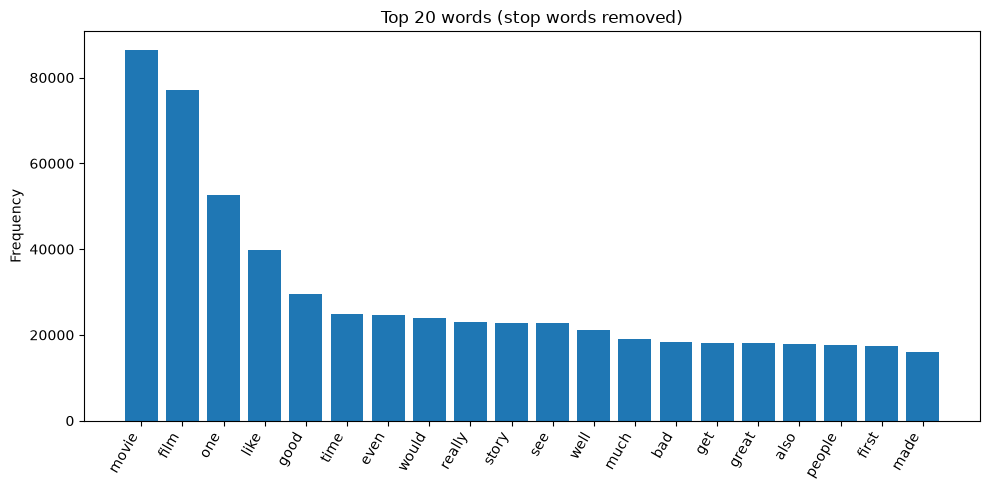

,word_with_stop,count_with_stop,word_no_stop,count_no_stop
0,the,662914,movie,86470
1,and,322088,film,77205
2,a,320776,one,52692
3,of,287338,like,39842
4,to,266103,good,29539
5,is,209633,time,24888
6,in,185410,even,24669
7,it,155832,would,24036
8,i,153792,really,22923
9,this,149799,story,22867


In [17]:
def top_words(tokens, n=20, remove_stop=False):
    if remove_stop:
        tokens = [w for w in tokens if w not in STOP and len(w) > 1]
    return pd.DataFrame(Counter(tokens).most_common(n), columns=["word", "count"])

def plot_top(tbl, title, filename):
    plt.figure(figsize=(10, 5))
    plt.bar(tbl["word"], tbl["count"])
    plt.xticks(rotation=60, ha="right")
    plt.title(title)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/figures/{filename}", dpi=150)
    plt.show()

top20_raw = top_words(all_tokens)
display(top20_raw)
plot_top(top20_raw, "Top 20 words (with stop words)", "top20_with_stopwords.png")

top20_clean = top_words(all_tokens, remove_stop=True)
display(top20_clean)
plot_top(top20_clean, "Top 20 words (stop words removed)", "top20_no_stopwords.png")

word_freq_comparison = pd.concat(
    [top20_raw.add_suffix("_with_stop"), top20_clean.add_suffix("_no_stop")],
    axis=1,
)
display(word_freq_comparison)

,word,count
0,movie,86470
1,film,77205
2,one,52692
3,like,39842
4,good,29539
5,time,24888
6,even,24669
7,would,24036
8,really,22923
9,story,22867


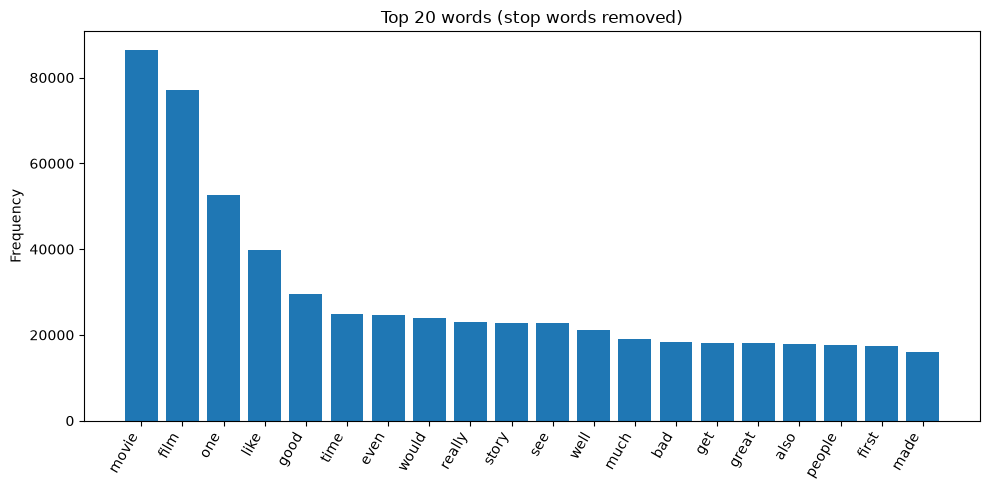

,word_with_stop,count_with_stop,word_no_stop,count_no_stop
0,the,662914,movie,86470
1,and,322088,film,77205
2,a,320776,one,52692
3,of,287338,like,39842
4,to,266103,good,29539
5,is,209633,time,24888
6,in,185410,even,24669
7,it,155832,would,24036
8,i,153792,really,22923
9,this,149799,story,22867


In [18]:
top20_clean = top_words(all_tokens, remove_stop=True)
display(top20_clean)
plot_top(top20_clean, 'Top 20 words (stop words removed)', 'top20_no_stopwords.png')

comparison = pd.concat([top20_raw.add_suffix('_with_stop'),
                        top20_clean.add_suffix('_no_stop')], axis=1)
comparison

In [19]:
group_stats = df.groupby('sentiment').agg(
    records=('clean_word_count', 'size'),
    avg_char_len=('clean_char_len', 'mean'),
    avg_word_count=('clean_word_count', 'mean')
).round(2)

group_stats

,records,avg_char_len,avg_word_count
sentiment,,,
negative,24698,1233.28,227.99
positive,24884,1266.92,231.75


In [20]:
pos_tokens = [w for t in df[df['sentiment'] == 'positive']['tokens'] for w in t]
neg_tokens = [w for t in df[df['sentiment'] == 'negative']['tokens'] for w in t]

top_pos = top_words(pos_tokens, n=10, remove_stop=True)
top_neg = top_words(neg_tokens, n=10, remove_stop=True)

print('--- positive ---')
display(top_pos)
print('--- negative ---')
display(top_neg)

--- positive ---


,word,count
0,film,40887
1,movie,37299
2,one,26918
3,like,17650
4,good,14965
5,great,12888
6,story,12835
7,time,12692
8,well,12682
9,see,12212


--- negative ---


,word,count
0,movie,49171
1,film,36318
2,one,25774
3,like,22192
4,even,15095
5,good,14574
6,bad,14563
7,would,13611
8,really,12216
9,time,12196


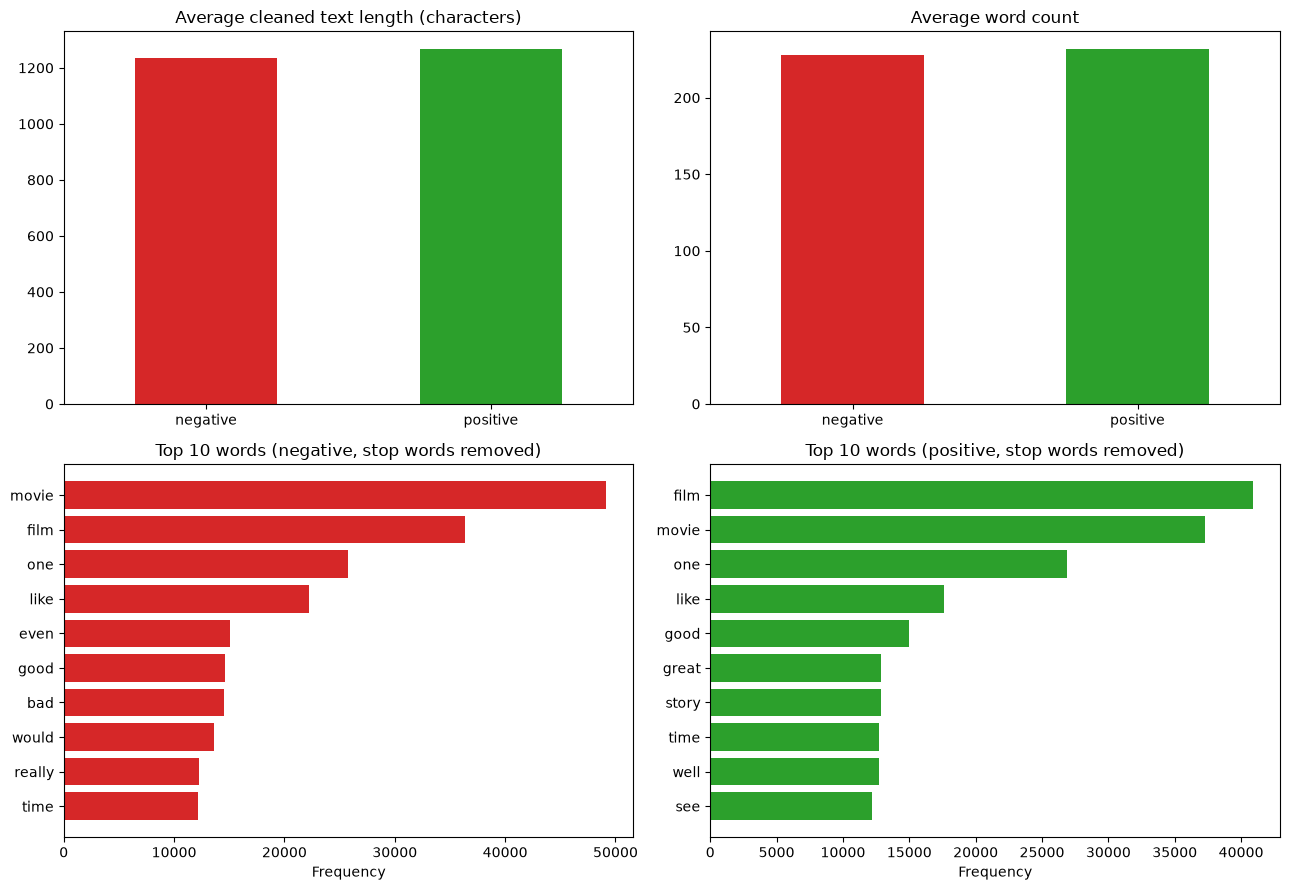

In [21]:
group_colors = {"negative": "tab:red", "positive": "tab:green"}
bar_colors = [group_colors[g] for g in group_stats.index]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
group_stats["avg_char_len"].plot.bar(ax=axes[0, 0], color=bar_colors, rot=0)
axes[0, 0].set_title("Average cleaned text length (characters)")
axes[0, 0].set_xlabel("")
group_stats["avg_word_count"].plot.bar(ax=axes[0, 1], color=bar_colors, rot=0)
axes[0, 1].set_title("Average word count")
axes[0, 1].set_xlabel("")

for ax, tbl, name in [(axes[1, 0], top_neg, "negative"), (axes[1, 1], top_pos, "positive")]:
    t = tbl.iloc[::-1]
    ax.barh(t["word"], t["count"], color=group_colors[name])
    ax.set_title(f"Top 10 words ({name}, stop words removed)")
    ax.set_xlabel("Frequency")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/group_comparison.png", dpi=150)
plt.show()

## Insights

**1. Stop words dominate raw word frequency**
- **Observation:** 18 of the 20 most frequent words are stop words.
- **Evidence:** "the" appears 662,914 times (about 5.8% of all 11,397,912 tokens), followed by "and" (322,088) and "a" (320,776). Only "movie" (86,470) and "film" (77,205) are content words.
- **Interpretation:** Raw counts mostly reflect English grammar, not review content, so stop-word removal is needed before the word list says anything useful.

**2. A tiny part of the vocabulary covers a large share of the text**
- **Observation:** Word usage is highly concentrated.
- **Evidence:** There are 109,472 unique words, but the top 20 words account for about 3.58 million tokens, roughly 31% of all tokens.
- **Interpretation:** This is the typical long-tail pattern of natural language: a few words repeat constantly, while most of the vocabulary (names, rare words, typos) appears only a few times.

**3. After stop-word removal, the top words describe the subject, not the opinion**
- **Observation:** The most frequent content words are the nouns for what is being reviewed.
- **Evidence:** "movie" (86,470) and "film" (77,205) lead, ahead of "one" (52,692), "like" (39,842) and "story" (22,867).
- **Interpretation:** Reviews are mostly about movies, stories and viewing experience. These topic words appear in both sentiment groups, so they cannot separate positive from negative on their own.

**4. Positive reviews favour "film", negative reviews favour "movie"**
- **Observation:** The two groups rank the same two words in opposite order.
- **Evidence:** In positive reviews "film" (40,887) beats "movie" (37,299), so "film" is 52.3% of the two words. In negative reviews "movie" (49,171) beats "film" (36,318), so "film" is only 42.5%.
- **Interpretation:** "Film" is the more formal, critic-style word and "movie" the more casual one, so word choice may hint at tone. This is a pattern in the counts, not proof, and would need further analysis to confirm.

**5. "bad" and "great" separate the groups better than "good"**
- **Observation:** "good" appears about equally in both groups, but "bad" and "great" lean strongly to one side.
- **Evidence:** "good" has 14,965 uses in positive and 14,574 in negative reviews (under 3% difference). "bad" is in the negative top 10 (14,563 of its 18,292 total, about 80%), and "great" is in the positive top 10 (12,888 of its 18,018 total, about 72%).
- **Interpretation:** "good" is often negated or used in contrasts ("not good", "good idea but..."), which plain word counts cannot capture. Strong polarity words like "bad" and "great" carry more sentiment signal and would be useful features for a classifier.

In [22]:
cleaned = df.drop(columns=["tokens", "cluster_id"], errors="ignore")
cleaned.to_csv(f"{OUTPUT_DIR}/cleaned_data.csv", index=False)
print("Saved cleaned_data.csv with shape", cleaned.shape)
cleaned.head(3)

Saved cleaned_data.csv with shape (49582, 10)


,review,sentiment,label,char_count,word_count,unique_word_count,avg_word_length,cleaned_text,clean_word_count,clean_char_len
0,One of the other reviewers has mentioned that ...,positive,1,1761,307,200,5.736156,one of the other reviewers has mentioned that ...,307,1676
1,A wonderful little production. <br /><br />The...,positive,1,998,162,112,6.160494,a wonderful little production the filming tech...,158,943
2,I thought this was a wonderful way to spend ti...,positive,1,926,166,120,5.578313,i thought this was a wonderful way to spend ti...,164,878


# Supervised text classification

In [23]:
ml_df = df[df["cleaned_text"].str.len() > 0]
X_train, X_test, y_train, y_test = train_test_split(
    ml_df["cleaned_text"], ml_df["label"],
    test_size=0.2, stratify=ml_df["label"], random_state=RANDOM_STATE)
print("Train:", len(X_train), "| Test:", len(X_test))
print("Positive share  train: %.4f  test: %.4f" % (y_train.mean(), y_test.mean()))

tfidf = TfidfVectorizer(token_pattern=TOKEN_PATTERN, min_df=5, max_df=0.9,
                        sublinear_tf=True, max_features=50_000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print("TF-IDF matrix:", X_train_tfidf.shape)


Train: 39665 | Test: 9917
Positive share  train: 0.5019  test: 0.5019
TF-IDF matrix: (39665, 34954)


In [24]:
# Model 1: Multinomial Naive Bayes
nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train)
nb_pred = nb.predict(X_test_tfidf)

# Model 2: Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr.fit(X_train_tfidf, y_train)
lr_pred = lr.predict(X_test_tfidf)

results_df = pd.DataFrame({
    "MultinomialNB":      [accuracy_score(y_test, nb_pred), precision_score(y_test, nb_pred),
                           recall_score(y_test, nb_pred), f1_score(y_test, nb_pred)],
    "LogisticRegression": [accuracy_score(y_test, lr_pred), precision_score(y_test, lr_pred),
                           recall_score(y_test, lr_pred), f1_score(y_test, lr_pred)],
}, index=["accuracy", "precision", "recall", "f1"]).round(4)
display(results_df)

,MultinomialNB,LogisticRegression
accuracy,0.8603,0.8968
precision,0.8731,0.8880
recall,0.8445,0.9092
f1,0.8585,0.8984


MultinomialNB
               precision    recall  f1-score   support

    negative     0.8483    0.8763    0.8621      4940
    positive     0.8731    0.8445    0.8585      4977

    accuracy                         0.8603      9917
   macro avg     0.8607    0.8604    0.8603      9917
weighted avg     0.8607    0.8603    0.8603      9917

LogisticRegression
               precision    recall  f1-score   support

    negative     0.9062    0.8844    0.8952      4940
    positive     0.8880    0.9092    0.8984      4977

    accuracy                         0.8968      9917
   macro avg     0.8971    0.8968    0.8968      9917
weighted avg     0.8971    0.8968    0.8968      9917



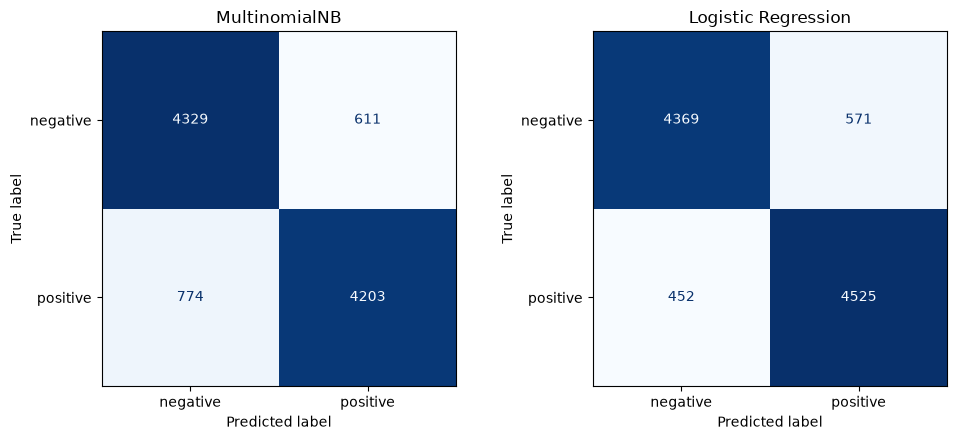

In [25]:
nb_report = classification_report(y_test, nb_pred, target_names=["negative", "positive"], digits=4)
lr_report = classification_report(y_test, lr_pred, target_names=["negative", "positive"], digits=4)
print("MultinomialNB\n", nb_report)
print("LogisticRegression\n", lr_report)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, nb_pred, display_labels=["negative", "positive"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("MultinomialNB")
ConfusionMatrixDisplay.from_predictions(y_test, lr_pred, display_labels=["negative", "positive"],
                                        cmap="Blues", ax=axes[1], colorbar=False)
axes[1].set_title("Logistic Regression")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/figures/confusion_matrix.png", dpi=150)
plt.show()

In [26]:
terms = np.array(tfidf.get_feature_names_out())
order = np.argsort(lr.coef_[0])
top_negative_terms = list(terms[order[:15]])
top_positive_terms = list(terms[order[-15:][::-1]])
print("Most negative terms:", top_negative_terms)
print("Most positive terms:", top_positive_terms)

Most negative terms: ['worst', 'bad', 'awful', 'waste', 'boring', 'poor', 'terrible', 'nothing', 'worse', 'horrible', 'poorly', 'dull', 'fails', 'stupid', 'disappointment']
Most positive terms: ['great', 'excellent', 'best', 'perfect', 'amazing', 'wonderful', 'loved', 'enjoyed', 'brilliant', 'fun', 'love', 'favorite', 'well', 'today', 'superb']


## K-Means clustering

In [27]:
tfidf_km = TfidfVectorizer(token_pattern=TOKEN_PATTERN, stop_words="english",
                           min_df=5, max_df=0.5, max_features=5000, sublinear_tf=True)
X_km = tfidf_km.fit_transform(ml_df["cleaned_text"])
print("TF-IDF matrix:", X_km.shape)
k_rows = []
for k in range(2, 16):
    km_try = KMeans(n_clusters=k, n_init=2, random_state=RANDOM_STATE).fit(X_km)
    sil = silhouette_score(X_km, km_try.labels_, sample_size=10000, random_state=RANDOM_STATE)
    k_rows.append({"k": k, "inertia": round(km_try.inertia_, 1), "silhouette": round(sil, 4)})
k_df = pd.DataFrame(k_rows)
display(k_df)

K_FINAL = int(k_df.loc[k_df["silhouette"].idxmax(), "k"])
print("Chosen k:", K_FINAL)

km = KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE).fit(X_km)
cluster_labels = km.labels_
final_sil = silhouette_score(X_km, cluster_labels, sample_size=10000, random_state=RANDOM_STATE)

cluster_sizes = pd.Series(cluster_labels).value_counts().sort_index()
print("Cluster sizes:\n", cluster_sizes.to_string())
print("Silhouette score: %.4f" % final_sil)


terms_km = np.array(tfidf_km.get_feature_names_out())
cluster_terms = {}
for c in range(K_FINAL):
    cluster_terms[c] = list(terms_km[km.cluster_centers_[c].argsort()[::-1][:12]])
    print(f"Cluster {c} ({cluster_sizes[c]} records): {', '.join(cluster_terms[c])}")


crosstab = pd.crosstab(pd.Series(cluster_labels, index=ml_df.index, name="cluster"), ml_df["sentiment"])
display(crosstab)
display(crosstab.div(crosstab.sum(axis=1), axis=0).round(3))

TF-IDF matrix: (49582, 5000)


,k,inertia,silhouette
0,2,47887.2,0.0020
1,3,47822.6,0.0001
2,4,47764.8,-0.0000
3,5,47718.1,-0.0001
4,6,47676.8,-0.0002
5,7,47641.8,-0.0000
6,8,47604.2,0.0001
7,9,47564.5,0.0005
8,10,47534.3,0.0006
9,11,47495.7,0.0003


Chosen k: 2
Cluster sizes:
 0    20098
1    29484
Silhouette score: 0.0020
Cluster 0 (20098 records): just, like, bad, it's, good, really, don't, movies, time, watch, think, acting
Cluster 1 (29484 records): story, great, like, good, it's, time, just, best, love, life, characters, films


sentiment,negative,positive
cluster,,
0,14728,5370
1,9970,19514


sentiment,negative,positive
cluster,,
0,0.733,0.267
1,0.338,0.662


In [28]:
CLUSTER_INTERPRETATION = """k was tested from 2 to 15 and k = 2 has the highest silhouette score (0.0020), and it also matches the two sentiment classes. However, every silhouette score is close to zero (the second best is 0.0008 at k = 15, and several are zero or slightly negative), and inertia falls by only about 1% across the whole range (47,887 to 47,391), so there is no elbow. The reviews do not form well-separated groups in TF-IDF space. A wider search up to k = 99 gave a nominal maximum at k = 92 (silhouette about 0.004), but that difference is within noise and its clusters were mostly narrow topic or genre groups.

Cluster 0 (20,098 reviews) has top terms such as just, like, bad, really, don't, movies, watch and acting. 73.3% of its reviews are negative. Cluster 1 (29,484 reviews) has top terms such as story, great, best, love, life, characters and films: more descriptive language about plot and characters, together with praise. 66.2% of its reviews are positive.

Compared with the known labels, the clusters follow sentiment only partly. 69.1% of reviews (34,242 of 49,582) fall in the cluster where their own sentiment is the majority. But cluster 1 still contains 9,970 negative reviews (about 40% of all negatives), so K-Means did not recover the classes. K-Means never sees the labels, and its clusters reflect a mix of sentiment words and writing style or topic."""


MODEL_INTERPRETATION = """Logistic Regression outperformed Multinomial Naive Bayes on every metric: accuracy 89.7% vs 86.0% and F1 0.898 vs 0.859. Naive Bayes assumes words are independent, which is unrealistic for text, while Logistic Regression learns a weight for each term and copes better with correlated words.

Naive Bayes is slightly unbalanced: its precision for the positive class (0.873) is higher than its recall (0.845), so it misses more positive reviews than it wrongly labels positive and leans toward predicting negative. Logistic Regression is more balanced (positive precision 0.888, recall 0.909; negative precision 0.906, recall 0.884), and both classes get similar F1 (0.895 negative, 0.898 positive), so its errors are spread evenly."""



with open(f"{OUTPUT_DIR}/model_metrics.txt", "w") as f:
    f.write("SUPERVISED TEXT CLASSIFICATION\n" + "=" * 70 + "\n\n")
    f.write(f"Train: {len(X_train)} | Test: {len(X_test)} (80/20, stratified, random_state={RANDOM_STATE})\n")
    f.write("Features: TF-IDF on cleaned_text (fit on training data only)\n")
    f.write("Precision, recall and F1 use the positive class (label 1).\n\n")
    f.write("MODEL COMPARISON (test set)\n" + results_df.to_string() + "\n\n")
    f.write("MULTINOMIAL NAIVE BAYES\n" + nb_report + "\n")
    f.write("Confusion matrix (rows = true neg/pos, cols = predicted neg/pos):\n" + str(confusion_matrix(y_test, nb_pred)) + "\n\n")
    f.write("LOGISTIC REGRESSION\n" + lr_report + "\n")
    f.write("Confusion matrix (rows = true neg/pos, cols = predicted neg/pos):\n" + str(confusion_matrix(y_test, lr_pred)) + "\n\n")
    f.write("MOST NEGATIVE TERMS (LR): " + ", ".join(top_negative_terms) + "\n")
    f.write("MOST POSITIVE TERMS (LR): " + ", ".join(top_positive_terms) + "\n\n")
    f.write("INTERPRETATION\n" + MODEL_INTERPRETATION + "\n\n")
    f.write("LIMITATIONS\n")
    f.write("1. TF-IDF is a bag of words: word order and context are lost, so negation, sarcasm and mixed reviews are hard.\n2. A single train/test split was used; cross-validation would give a more reliable estimate.\n")
print("Saved model_metrics.txt")

with open(f"{OUTPUT_DIR}/cluster_summary.txt", "w") as f:
    f.write("K-MEANS CLUSTERING\n" + "=" * 70 + "\n\n")
    f.write(f"Records clustered: {len(ml_df)} | Features: TF-IDF (stop words removed, 5000 terms)\n\n")
    f.write("k SELECTION (k = 2 to 15)\n" + k_df.to_string(index=False) + "\n\n")
    f.write(f"Chosen k: {K_FINAL} (highest silhouette)\n")
    f.write(f"Silhouette score (20,000-record random sample): {final_sil:.4f}\n\n")
    f.write("CLUSTER SIZES\n" + cluster_sizes.to_string() + "\n\n")
    f.write("TOP TERMS PER CLUSTER\n")
    for c in range(K_FINAL):
        f.write(f"Cluster {c} ({cluster_sizes[c]} records): {', '.join(cluster_terms[c])}\n")
    f.write("\nCOMPARISON WITH SENTIMENT LABELS (rows = clusters)\n" + crosstab.to_string() + "\n\n")
    f.write("INTERPRETATION\n" + CLUSTER_INTERPRETATION + "\n")
print("Saved cluster_summary.txt")

Saved model_metrics.txt
Saved cluster_summary.txt
